# When should a human take over?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/llmops-genai-platform/human-escalation-policy/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=llmops-genai-platform/human-escalation-policy/demo.ipynb)

An AI support agent handles 10,000 tickets a day and reports a confidence for each one. Below some cutoff, the
ticket goes to a human. This notebook prices that cutoff by the cost of the error a review prevents, and then adds
the two things textbook escalation rules leave out: the human team has a daily capacity, and humans make more
mistakes as their queue fills. Everything is a constructed, declared world, and every cost is exact.

1. The engine
2. Calibration - exact vs simulation
3. The segments: same agent, three prices of being wrong
4. What one review is worth
5. Seven policies, one day
6. Escalating more is not always safer
7. Same skill, louder confidence
8. The chart
9. Try your own

## 1. The engine

Extracted from `escalation.py` at build time. Reported confidence lives on 40 bins. Each segment declares an
underlying score x ~ Beta(a, b), a true accuracy x ** gamma (gamma > 1 is overconfident), and a reporting
inflation x ** (1 / k). A policy is one cutoff per segment. Escalations past capacity time out and the agent acts.

In [1]:
from __future__ import annotations

import math
from typing import Dict, List, Optional

import matplotlib.pyplot as plt
import numpy as np

SEED = 195


MC_DAYS = 40


BINS = 40


CENTERS = (np.arange(BINS) + 0.5) / BINS  # stated confidence of each bin


SEGMENTS: Dict[str, Dict[str, float]] = {
    "refund": {"share": 0.15, "cost": 120.0, "a": 14.0, "b": 1.8, "gamma": 1.9, "inflate": 1.0},
    "account": {"share": 0.25, "cost": 40.0, "a": 16.0, "b": 1.8, "gamma": 1.3, "inflate": 1.0},
    "faq": {"share": 0.60, "cost": 3.0, "a": 20.0, "b": 1.8, "gamma": 1.0, "inflate": 1.0},
}


SEGS = list(SEGMENTS)


BASE: Dict[str, float] = {
    "tickets": 10_000.0,  # per day
    "review_cost": 6.0,  # $ of agent time per human review
    "capacity": 700.0,  # reviews a day the team can do
    "human_err": 0.03,  # human error rate with a calm queue
    "human_err_full": 0.12,  # human error rate at 100% utilisation
    "calm_until": 0.70,  # utilisation below which humans stay at human_err
}


FINE = 50


_CACHE: Dict[tuple, Dict[str, Dict[str, np.ndarray]]] = {}


def segment_tables(segments: Optional[Dict[str, Dict[str, float]]] = None) -> Dict[str, Dict[str, np.ndarray]]:
    seg = segments or SEGMENTS
    key = tuple((s, tuple(sorted(v.items()))) for s, v in seg.items())
    if key not in _CACHE:
        _CACHE[key] = _tables(seg)
    return _CACHE[key]


def _tables(seg: Dict[str, Dict[str, float]]) -> Dict[str, Dict[str, np.ndarray]]:
    """Per segment: mass of REPORTED confidence on the bin grid, and true accuracy within each bin.

    The underlying score is integrated on a fine midpoint grid; each fine point reports x ** (1 / inflate) and is
    correct with probability x ** gamma, so a bin's accuracy is the mass-weighted mean over the points it receives."""
    x = (np.arange(BINS * FINE) + 0.5) / (BINS * FINE)
    out = {}
    for s, v in seg.items():
        logd = (v["a"] - 1) * np.log(x) + (v["b"] - 1) * np.log1p(-x)
        d = np.exp(logd - logd.max())
        d /= d.sum()
        reported = x ** (1 / v.get("inflate", 1.0))
        b = np.minimum((reported * BINS).astype(int), BINS - 1)
        pmf = np.bincount(b, weights=d, minlength=BINS)
        hit = np.bincount(b, weights=d * x ** v["gamma"], minlength=BINS)
        p_true = np.divide(hit, pmf, out=np.zeros(BINS), where=pmf > 0)
        out[s] = {"pmf": pmf, "p_true": p_true}
    return out


def human_error(util: float, prm: Dict[str, float]) -> float:
    """Calm until calm_until, then rising linearly to human_err_full at 100% and staying there."""
    lo, hi, k = prm["human_err"], prm["human_err_full"], prm["calm_until"]
    if util <= k:
        return lo
    return lo + (hi - lo) * min(1.0, (util - k) / (1 - k))


def evaluate(thr: Dict[str, float], prm: Optional[Dict[str, float]] = None,
             segments: Optional[Dict[str, Dict[str, float]]] = None) -> Dict[str, float]:
    """Exact expected day under a threshold policy: escalate when stated confidence < thr[segment]."""
    prm = prm or BASE
    seg = segments or SEGMENTS
    tab = segment_tables(seg)
    n = prm["tickets"]
    esc = {s: float(n * seg[s]["share"] * tab[s]["pmf"][CENTERS < thr[s]].sum()) for s in seg}
    e_total = sum(esc.values())
    reviewed = min(1.0, prm["capacity"] / e_total) if e_total > 0 else 1.0
    util = min(e_total, prm["capacity"]) / prm["capacity"]
    h = human_error(util, prm)
    cost = review = 0.0
    errors = {}
    by_seg = {}
    for s in seg:
        c, pm, pt = seg[s]["cost"], tab[s]["pmf"], tab[s]["p_true"]
        mask = CENTERS < thr[s]
        ns = n * seg[s]["share"]
        auto_err = ns * float((pm * (1 - pt))[~mask].sum())
        esc_model_err = ns * float((pm * (1 - pt))[mask].sum())  # if these went back to the agent
        human_cases = esc[s] * reviewed
        err = auto_err + human_cases * h + (1 - reviewed) * esc_model_err
        errors[s] = err
        by_seg[s] = err * c
        cost += err * c
        review += human_cases * prm["review_cost"]
    return {
        "cost": cost + review, "error_cost": cost, "review_cost": review, "escalated": e_total,
        "escalation_rate": e_total / n, "reviewed_share": reviewed, "utilisation": util, "human_err": h,
        "errors": errors, "error_cost_by_seg": by_seg, "esc_by_seg": esc,
        "error_rate": sum(errors.values()) / n,
    }


def chow_threshold(cost: float, prm: Dict[str, float], gamma: float = 1.0) -> float:
    """Escalate iff (1 - p) * cost > review_cost + human_err * cost, with p = c ** gamma.

    gamma = 1 trusts the stated confidence; the segment's true gamma uses the calibrated probability.
    Returns the stated-confidence cutoff (escalate below it)."""
    p_star = 1 - (prm["review_cost"] + prm["human_err"] * cost) / cost
    if p_star <= 0:
        return 0.0
    return float(p_star ** (1 / gamma))


def snap(t: float) -> float:
    """Thresholds act on bin centres; snap to the bin edge at or above t so policies are comparable."""
    return float(min(1.0, math.ceil(t * BINS - 1e-9) / BINS))


EDGES = [i / BINS for i in range(BINS + 1)]


def best_global(prm: Optional[Dict[str, float]] = None) -> Dict[str, float]:
    prm = prm or BASE
    best = min(EDGES, key=lambda t: evaluate({s: t for s in SEGS}, prm)["cost"])
    return {s: best for s in SEGS}


def best_per_segment(prm: Optional[Dict[str, float]] = None,
                     segments: Optional[Dict[str, Dict[str, float]]] = None) -> Dict[str, float]:
    """Joint grid search over the three thresholds (capacity couples them, so they cannot be optimised apart)."""
    prm = prm or BASE
    best, best_c = None, float("inf")
    for a in EDGES:
        for b in EDGES:
            for c in EDGES[: BINS // 2 + 1]:
                thr = {"refund": a, "account": b, "faq": c}
                v = evaluate(thr, prm, segments)["cost"]
                if v < best_c:
                    best, best_c = thr, v
    return best


def rate_target(rate: float, prm: Optional[Dict[str, float]] = None) -> Dict[str, float]:
    """One global cutoff chosen so the escalation rate is as close as possible to `rate` (a staffing target)."""
    prm = prm or BASE
    t = min(EDGES, key=lambda t: abs(evaluate({s: t for s in SEGS}, prm)["escalation_rate"] - rate))
    return {s: t for s in SEGS}


def policies(prm: Optional[Dict[str, float]] = None) -> Dict[str, Dict[str, float]]:
    prm = prm or BASE
    return {
        "never escalate": {s: 0.0 for s in SEGS},
        "accuracy rule: conf < 0.90": {s: 0.90 for s in SEGS},
        "staffing rule: fill capacity": rate_target(prm["capacity"] / prm["tickets"], prm),
        "best single threshold": best_global(prm),
        "priced, stated confidence": {s: snap(chow_threshold(SEGMENTS[s]["cost"], prm)) for s in SEGS},
        "priced, calibrated": {s: snap(chow_threshold(SEGMENTS[s]["cost"], prm, SEGMENTS[s]["gamma"])) for s in SEGS},
        "priced + capacity (joint)": best_per_segment(prm),
    }


def policy_table(prm: Optional[Dict[str, float]] = None) -> List[Dict[str, object]]:
    prm = prm or BASE
    rows = []
    for name, thr in policies(prm).items():
        r = evaluate(thr, prm)
        rows.append({"policy": name, "thr": thr, **{k: r[k] for k in (
            "cost", "error_cost", "review_cost", "escalated", "escalation_rate", "reviewed_share", "utilisation",
            "human_err", "error_rate")}, "error_cost_by_seg": r["error_cost_by_seg"], "esc_by_seg": r["esc_by_seg"]})
    return rows


def load_curve(prm: Optional[Dict[str, float]] = None, points: int = 13) -> List[Dict[str, float]]:
    """Scale the calibrated priced thresholds up and down: does escalating MORE always make the day safer?"""
    prm = prm or BASE
    base = {s: chow_threshold(SEGMENTS[s]["cost"], prm, SEGMENTS[s]["gamma"]) for s in SEGS}
    rows = []
    for i in range(points):
        k = 0.6 + 0.6 * i / (points - 1)  # 0.6x .. 1.2x of each priced cutoff
        thr = {s: min(1.0, base[s] * k) for s in SEGS}
        r = evaluate(thr, prm)
        rows.append({"scale": k, "escalated": r["escalated"], "utilisation_demand": r["escalated"] / prm["capacity"],
                     "cost": r["cost"], "errors": sum(r["errors"].values()), "human_err": r["human_err"]})
    return rows


INFLATE_V2 = 2.0  # the new model reports sqrt-shaped confidence: 0.81 skill now reads 0.90


def upgrade(prm: Optional[Dict[str, float]] = None) -> Dict[str, Dict[str, float]]:
    """A model upgrade with identical skill that REPORTS higher confidence (every segment inflated).

    Same thresholds before and after (the policy did not change, only the model did)."""
    prm = prm or BASE
    v2 = {s: dict(v) for s, v in SEGMENTS.items()}
    for s in v2:
        v2[s]["inflate"] = INFLATE_V2
    thr = best_per_segment(prm)
    before = evaluate(thr, prm)
    after = evaluate(thr, prm, v2)
    thr2 = best_per_segment(prm, v2)
    refit = evaluate(thr2, prm, v2)
    keep = ("cost", "escalation_rate", "error_rate", "escalated")

    def row(r: Dict[str, object]) -> Dict[str, float]:
        out = {k: float(r[k]) for k in keep}
        out["refund_err_cost"] = float(r["error_cost_by_seg"]["refund"])
        return out

    return {"before": row(before), "after": row(after), "refit": row(refit), "thr": thr, "thr_refit": thr2}


def value_curve(prm: Optional[Dict[str, float]] = None) -> Dict[str, List[float]]:
    """Expected dollars one human review saves, per segment and reported-confidence bin, with a calm queue:
    (1 - p) * cost  -  (review_cost + human_err * cost). Positive means the review pays for itself."""
    prm = prm or BASE
    tab = segment_tables()
    out = {}
    for s in SEGS:
        c = SEGMENTS[s]["cost"]
        v = (1 - tab[s]["p_true"]) * c - (prm["review_cost"] + prm["human_err"] * c)
        out[s] = [float(x) if m > 0 else float("nan") for x, m in zip(v, tab[s]["pmf"])]
    return out


def simulate(thr: Dict[str, float], prm: Optional[Dict[str, float]] = None, days: int = MC_DAYS,
             seed: int = SEED) -> Dict[str, Dict[str, float]]:
    """Whole days, ticket by ticket. Overflow picks escalations to time out uniformly at random."""
    prm = prm or BASE
    rng = np.random.default_rng(seed)
    tab = segment_tables()
    n = int(prm["tickets"])
    tot = {s: [0, 0] for s in SEGS}  # errors, tickets
    for _ in range(days):
        seg_idx = rng.choice(len(SEGS), size=n, p=[SEGMENTS[s]["share"] for s in SEGS])
        bins = np.empty(n, dtype=int)
        for i, s in enumerate(SEGS):
            m = seg_idx == i
            bins[m] = rng.choice(BINS, size=int(m.sum()), p=tab[s]["pmf"])
        conf = CENTERS[bins]
        ptab = np.stack([tab[s]["p_true"] for s in SEGS])
        model_ok = rng.random(n) < ptab[seg_idx, bins]
        cut = np.array([thr[s] for s in SEGS])
        esc = conf < cut[seg_idx]
        e = int(esc.sum())
        reviewed = np.zeros(n, dtype=bool)
        if e:
            idx = np.flatnonzero(esc)
            k = min(e, int(prm["capacity"]))
            reviewed[rng.choice(idx, size=k, replace=False)] = True
        util = min(e, prm["capacity"]) / prm["capacity"]
        h = human_error(util, prm)
        human_ok = rng.random(n) >= h
        wrong = np.where(reviewed, ~human_ok, ~model_ok)
        for i, s in enumerate(SEGS):
            m = seg_idx == i
            tot[s][0] += int(wrong[m].sum())
            tot[s][1] += int(m.sum())
    return {s: {"errors": tot[s][0], "tickets": tot[s][1]} for s in SEGS}


def wilson(k: int, n: int, z: float = 2.5758) -> tuple:
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h


def calibrate(prm: Optional[Dict[str, float]] = None) -> List[Dict[str, object]]:
    """Exact per-segment error rates vs the simulation, for every policy."""
    prm = prm or BASE
    rows = []
    for name, thr in policies(prm).items():
        ex = evaluate(thr, prm)
        mc = simulate(thr, prm)
        for s in SEGS:
            exact = ex["errors"][s] / (prm["tickets"] * SEGMENTS[s]["share"])
            k, n = mc[s]["errors"], mc[s]["tickets"]
            lo, hi = wilson(k, n)
            rows.append({"policy": name, "segment": s, "exact": exact, "mc": k / n, "inside": bool(lo <= exact <= hi)})
    return rows


def parse_params(text: str) -> Dict[str, float]:
    """`key=value, key=value` overrides of BASE. Unknown keys and bad numbers raise ValueError."""
    prm = dict(BASE)
    for part in [p.strip() for p in text.split(",") if p.strip()]:
        if "=" not in part:
            raise ValueError(f"expected key=value, got {part!r}")
        k, v = [x.strip() for x in part.split("=", 1)]
        if k not in BASE:
            raise ValueError(f"unknown parameter {k!r}; known: {', '.join(BASE)}")
        try:
            prm[k] = float(v)
        except ValueError:
            raise ValueError(f"{k} needs a number, got {v!r}") from None
    if prm["capacity"] <= 0 or prm["tickets"] <= 0:
        raise ValueError("capacity and tickets must be positive")
    if not 0 <= prm["human_err"] <= prm["human_err_full"] <= 1:
        raise ValueError("need 0 <= human_err <= human_err_full <= 1")
    return prm

## 2. Calibration - exact vs simulation

`simulate` plays whole days ticket by ticket: draw a segment and a confidence, draw whether the agent is right,
pick which escalations a full queue drops, draw whether the human is right. Each exact per-segment error rate
should sit inside the 99% Wilson interval of the simulated share.

**Resolution of the instrument.** The study in `evidence.txt` simulates 40 days; this notebook simulates
8 so it runs in seconds, which makes its intervals about 2x wider. The exact numbers below do not depend
on this.

In [2]:
rows = []
for name, thr in policies().items():
    ex = evaluate(thr)
    mc = simulate(thr, days=8)
    for s in SEGS:
        exact = ex["errors"][s] / (BASE["tickets"] * SEGMENTS[s]["share"])
        lo, hi = wilson(mc[s]["errors"], mc[s]["tickets"])
        rows.append(lo <= exact <= hi)
print(f"{sum(rows)}/{len(rows)} exact error rates inside the simulation's 99% Wilson interval")

21/21 exact error rates inside the simulation's 99% Wilson interval


## 3. The segments: same agent, three prices of being wrong

A wrong refund decision costs $120, a wrong account change $40, a wrong FAQ answer $3. The agent is least accurate
exactly where errors cost most, and it is most overconfident there too: on refunds it reports 88.6% and is right
80.0% of the time.

In [3]:
tab = segment_tables()
print(f"{'segment':<9} {'share':>6} {'cost of a wrong action':>23} {'true accuracy':>14} {'mean reported conf':>19}")
for s in SEGS:
    v = SEGMENTS[s]
    acc = float((tab[s]["pmf"] * tab[s]["p_true"]).sum())
    conf = float((tab[s]["pmf"] * CENTERS).sum())
    print(f"{s:<9} {v['share']:>6.0%} {'$' + format(v['cost'], '.0f'):>23} {acc:>14.1%} {conf:>19.1%}")

segment    share  cost of a wrong action  true accuracy  mean reported conf
refund       15%                    $120          80.0%               88.6%
account      25%                     $40          87.2%               89.9%
faq          60%                      $3          91.7%               91.7%


## 4. What one review is worth

With a calm queue, sending a ticket to a human saves (1 - p) * cost and spends the review plus the human's own
error rate times the cost. That is Chow's reject rule with a fallible reviewer. A FAQ review never pays for itself:
the best FAQ ticket a human could see is still a $3 problem.

In [4]:
vc = value_curve()
for s in SEGS:
    vals = [(c, v) for c, v in zip(CENTERS, vc[s]) if v == v]
    pos = [c for c, v in vals if v > 0]
    hi = f"pays below conf {max(pos) + 0.5 / BINS:.3f}" if pos else "never pays"
    print(f"   {s:<8} {hi:<26} best bin ${max(v for _, v in vals):.1f}")

   refund   pays below conf 0.950      best bin $110.3
   account  pays below conf 0.850      best bin $32.5
   faq      never pays                 best bin $-3.2


## 5. Seven policies, one day

The common rule (escalate anything under 90% confidence) sends 3,655 tickets to a 700-a-day team and costs MORE
than never escalating. Pricing each segment with Chow's rule is right on paper and still loses to one plain cutoff,
because it asks for two to three times the team's capacity. The policy that wins prices the errors AND respects
capacity: every review goes to refunds, and the queue stops at 79% full, before humans start to slip.

In [5]:
table = policy_table()
never = table[0]
print(f"{'policy':<28} {'escalated':>9} {'reviewed':>9} {'human err':>10} {'error rate':>11} {'cost/day':>9} {'vs never':>9}")
for r in table:
    print(f"{r['policy']:<28} {r['escalated']:>9.0f} {r['reviewed_share']:>9.0%} {r['human_err']:>10.1%} "
          f"{r['error_rate']:>11.2%} {'$' + format(r['cost'], ',.0f'):>9} {r['cost'] / never['cost'] - 1:>+9.1%}")

policy                       escalated  reviewed  human err  error rate  cost/day  vs never
never escalate                       0      100%       3.0%      11.16%   $50,341     +0.0%
accuracy rule: conf < 0.90        3655       19%      12.0%      10.61%   $50,712     +0.7%
staffing rule: fill capacity       709       99%      12.0%       9.75%   $44,998    -10.6%
best single threshold              447      100%       3.0%       9.71%   $43,633    -13.3%
priced, stated confidence         1300       54%      12.0%      10.08%   $44,063    -12.5%
priced, calibrated                2140       33%      12.0%      10.45%   $48,277     -4.1%
priced + capacity (joint)          551      100%       5.6%       9.62%   $35,153    -30.2%


## 6. Escalating more is not always safer

Scale the calibrated priced cutoffs from 0.6x to 1.2x. Cost falls while the queue has room, bottoms out at 80% of
capacity, then climbs as overflow and tired reviewers eat the gain.

In [6]:
for r in load_curve():
    print(f"scale {r['scale']:.2f}  escalated {r['escalated']:>5.0f}  demand {r['utilisation_demand']:>5.2f}x  "
          f"human err {r['human_err']:.1%}  ${r['cost']:,.0f}/day")

scale 0.60  escalated     4  demand  0.01x  human err 3.0%  $50,092/day
scale 0.65  escalated    11  demand  0.02x  human err 3.0%  $49,675/day
scale 0.70  escalated    29  demand  0.04x  human err 3.0%  $48,725/day
scale 0.75  escalated    75  demand  0.11x  human err 3.0%  $46,822/day
scale 0.80  escalated   162  demand  0.23x  human err 3.0%  $43,586/day
scale 0.85  escalated   351  demand  0.50x  human err 3.0%  $38,588/day
scale 0.90  escalated   558  demand  0.80x  human err 5.9%  $36,900/day
scale 0.95  escalated  1089  demand  1.56x  human err 12.0%  $42,668/day
scale 1.00  escalated  1698  demand  2.43x  human err 12.0%  $46,334/day
scale 1.05  escalated  2555  demand  3.65x  human err 12.0%  $49,563/day
scale 1.10  escalated  3350  demand  4.79x  human err 12.0%  $50,910/day
scale 1.15  escalated  3764  demand  5.38x  human err 12.0%  $51,529/day
scale 1.20  escalated  4000  demand  5.71x  human err 12.0%  $51,871/day


## 7. Same skill, louder confidence

A new model version is exactly as accurate and reports higher numbers (0.81 skill now reads 0.90). Keep the same
cutoffs and the escalation rate falls from 5.5% to 1.2%. A deflection dashboard calls that a win; the day costs 27%
more, almost all of it refunds the humans no longer see. Refitting the cutoffs on labels from the new version brings
the cost back. A threshold belongs to a model version, not to the product.

In [7]:
u = upgrade()
print(f"{'':<22} {'escalation rate':>16} {'error rate':>11} {'refund error $':>15} {'cost/day':>10}")
for k, label in (("before", "v1, joint thresholds"), ("after", "v2, same thresholds"), ("refit", "v2, refitted")):
    r = u[k]
    print(f"{label:<22} {r['escalation_rate']:>16.2%} {r['error_rate']:>11.2%} {'$' + format(r['refund_err_cost'], ',.0f'):>15} "
          f"{'$' + format(r['cost'], ',.0f'):>10}")

                        escalation rate  error rate  refund error $   cost/day
v1, joint thresholds              5.51%       9.62%         $17,520    $35,153
v2, same thresholds               1.21%      10.62%         $29,482    $44,534
v2, refitted                      4.91%       9.52%         $18,758    $35,192


## 8. The chart

The full audit figure is `escalation_audit.png` (built by `make_chart.py` from `results.json`). Here, the cost of a
day as the queue fills, for the calibrated priced rule scaled up and down.

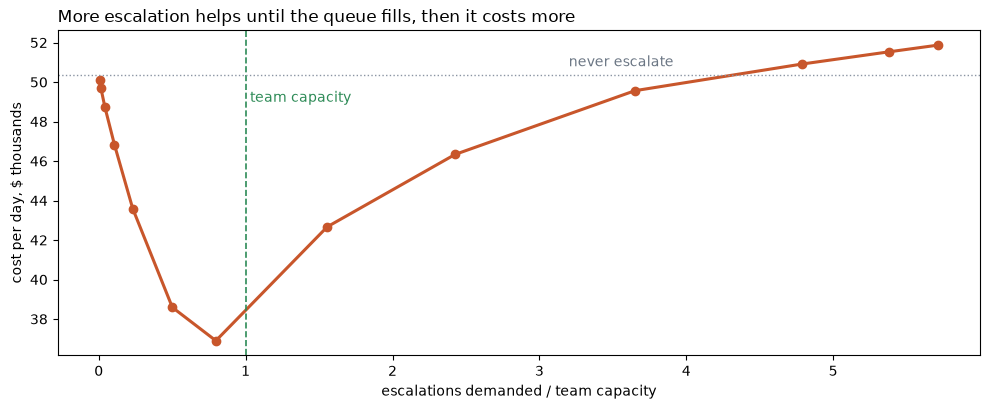

In [8]:
lc = load_curve()
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot([r["utilisation_demand"] for r in lc], [r["cost"] / 1000 for r in lc], color="#c8562b", lw=2.2, marker="o")
ax.axvline(1.0, color="#2e8b57", ls="--", lw=1.2)
ax.text(1.03, 49, "team capacity", color="#2e8b57")
ax.axhline(policy_table()[0]["cost"] / 1000, color="#8a94a3", ls=":", lw=1)
ax.text(3.2, 50.8, "never escalate", color="#6b7684")
ax.set_xlabel("escalations demanded / team capacity")
ax.set_ylabel("cost per day, $ thousands")
ax.set_title("More escalation helps until the queue fills, then it costs more", loc="left")
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- The common rule, escalate below 90% confidence, costs 0.7% MORE than never escalating: it floods a 700/day team
  with 3,655 tickets, the queue drops 81% of them, and the reviewers it does reach make 12% errors.
- Pricing each segment by the error it prevents is right on paper. With capacity binding, it loses to one cutoff
  ($48,277 vs $43,633), because calibration reveals more cases worth a review than the team can take.
- Pricing AND respecting capacity wins: $35,153/day, 19.4% below the best single cutoff, all 551 reviews on refunds,
  queue 79% full.
- With unlimited capacity the textbook priced rule is within about 1% of the optimum. The trap is the ceiling.
- Same skill, louder confidence: escalations 5.5% -> 1.2%, cost +27%. Refit cutoffs on every model version.

## 9. Try your own

In [9]:
# Your team, your prices, e.g. a bigger team with slower, careful reviewers:
# mine = parse_params("capacity=1500, review_cost=12, human_err=0.02")
# for r in policy_table(mine): print(r["policy"], round(r["escalated"]), round(r["cost"]))

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version takes your
own team: `pip install -r requirements.txt && streamlit run app.py`.

Sibling builds: [`threshold-explorer`](../../ml-engineering-toolkit/threshold-explorer) picks one binary cutoff with
two error prices; [`calibration-checker`](../../ml-engineering-toolkit/calibration-checker) asks whether a 0.9
means 90%. This build adds a human team with a ceiling and its own error rate.
[`refusal-rate-monitor`](../refusal-rate-monitor) is an earlier audit of a rate that moved for the wrong reason.